# Лабораторна 3

Знайомство з нейронними мережами (PyTorch).

1. MLP на табличних даних - MAGIC Gamma Telescope з лаби 1.
2. CNN на зображеннях - EuroSAT (супутникові знімки, 10 класів).
3. RNN для текстів - AG News з лаби 2 (3 класи).

In [1]:
import time, re, copy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset
import torchvision
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

torch.manual_seed(42)
np.random.seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.__version__)

cuda 2.6.0+cu124


Спільна функція навчання - щоб не повторювати цикл три рази. Після кожної епохи рахую loss і accuracy на train і на validation, і запамʼятовую ваги з найменшим val loss.

In [2]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            total += len(yb)
    return loss_sum / total, correct / total


def train_model(model, train_loader, val_loader, epochs, lr=1e-3, weight_decay=0.0, params=None):
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best, best_state = 1e9, None
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        total, correct, loss_sum = 0, 0, 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            total += len(yb)
        vl, va = evaluate(model, val_loader, loss_fn)
        hist['train_loss'].append(loss_sum / total); hist['train_acc'].append(correct / total)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if vl < best:
            best, best_state = vl, copy.deepcopy(model.state_dict())
        print(f'ep {ep+1:2d}  train loss {loss_sum/total:.4f} acc {correct/total:.4f} | val loss {vl:.4f} acc {va:.4f}')
    hist['time'] = time.time() - t0
    model.load_state_dict(best_state)
    return hist


def plot_hist(hists, title=''):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for name, h in hists.items():
        ep = range(1, len(h['train_loss']) + 1)
        l, = ax[0].plot(ep, h['train_loss'], label=f'{name} train')
        ax[0].plot(ep, h['val_loss'], '--', color=l.get_color(), label=f'{name} val')
        ax[1].plot(ep, h['train_acc'], color=l.get_color(), label=f'{name} train')
        ax[1].plot(ep, h['val_acc'], '--', color=l.get_color(), label=f'{name} val')
    ax[0].set_title(f'{title} loss'); ax[1].set_title(f'{title} accuracy')
    ax[0].set_xlabel('епоха'); ax[1].set_xlabel('епоха')
    ax[0].legend(); ax[1].legend()
    plt.show()


def predict(model, loader):
    model.eval()
    ps, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            ps.append(model(xb.to(device)).argmax(1).cpu()); ys.append(yb)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

## 1. Повнозвʼязана мережа (MLP) на MAGIC

In [3]:
cols = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
df = pd.read_csv('../lab1/magic04.data', header=None, names=cols).drop_duplicates()
df['class'] = LabelEncoder().fit_transform(df['class'])   # g = 0, h = 1
X = df.drop(columns='class').values
y = df['class'].values

# такий самий split як в лабі 1 (75/25, random_state=42), а з train ще відрізаю 15% на validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42, stratify=y_train)

scaler = StandardScaler().fit(X_tr)
to_t = lambda a, b: TensorDataset(torch.tensor(scaler.transform(a), dtype=torch.float32), torch.tensor(b))
tr_loader = DataLoader(to_t(X_tr, y_tr), batch_size=128, shuffle=True)
val_loader = DataLoader(to_t(X_val, y_val), batch_size=1024)
test_loader = DataLoader(to_t(X_test, y_test), batch_size=1024)
print(len(X_tr), len(X_val), len(X_test))

12051 2127 4727


Тестова частина та сама, що в лабі 1, щоб порівняння з класичними моделями було чесним. Validation потрібна для learning curves і щоб вибрати найкращу епоху, test не чіпаю до кінця.

In [4]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(128, 64), dropout=0.0, n_out=2):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

mlp_big = MLP(10, hidden=(256, 256, 128), dropout=0.0)
h_big = train_model(mlp_big, tr_loader, val_loader, epochs=60, lr=1e-3)

ep  1  train loss 0.4005 acc 0.8261 | val loss 0.3597 acc 0.8467
ep  2  train loss 0.3385 acc 0.8623 | val loss 0.3595 acc 0.8406


ep  3  train loss 0.3226 acc 0.8668 | val loss 0.3427 acc 0.8543
ep  4  train loss 0.3160 acc 0.8686 | val loss 0.3291 acc 0.8590


ep  5  train loss 0.3082 acc 0.8725 | val loss 0.3366 acc 0.8594


ep  6  train loss 0.3039 acc 0.8741 | val loss 0.3299 acc 0.8594


ep  7  train loss 0.2987 acc 0.8761 | val loss 0.3205 acc 0.8622
ep  8  train loss 0.2942 acc 0.8775 | val loss 0.3262 acc 0.8594


ep  9  train loss 0.2926 acc 0.8792 | val loss 0.3307 acc 0.8604
ep 10  train loss 0.2943 acc 0.8789 | val loss 0.3301 acc 0.8618


... (23 outputs left out)

ep 53  train loss 0.1375 acc 0.9445 | val loss 0.5162 acc 0.8594
ep 54  train loss 0.1357 acc 0.9444 | val loss 0.5038 acc 0.8566


ep 55  train loss 0.1446 acc 0.9403 | val loss 0.4813 acc 0.8524
ep 56  train loss 0.1337 acc 0.9466 | val loss 0.5325 acc 0.8594


ep 57  train loss 0.1263 acc 0.9493 | val loss 0.5000 acc 0.8505
ep 58  train loss 0.1276 acc 0.9467 | val loss 0.5144 acc 0.8561


ep 59  train loss 0.1182 acc 0.9512 | val loss 0.5146 acc 0.8496
ep 60  train loss 0.1428 acc 0.9419 | val loss 0.5526 acc 0.8524


Спочатку навмисно велика мережа без регуляризації (3 шари 256-256-128, ~100 тис. параметрів) і багато епох - подивитись, чи буде перенавчання.

ep  1  train loss 0.4632 acc 0.7944 | val loss 0.3925 acc 0.8213
ep  2  train loss 0.3854 acc 0.8337 | val loss 0.3733 acc 0.8350


ep  3  train loss 0.3686 acc 0.8420 | val loss 0.3610 acc 0.8397
ep  4  train loss 0.3580 acc 0.8476 | val loss 0.3539 acc 0.8449


ep  5  train loss 0.3496 acc 0.8572 | val loss 0.3477 acc 0.8467
ep  6  train loss 0.3431 acc 0.8571 | val loss 0.3447 acc 0.8557


ep  7  train loss 0.3393 acc 0.8603 | val loss 0.3414 acc 0.8547
ep  8  train loss 0.3367 acc 0.8634 | val loss 0.3402 acc 0.8543


ep  9  train loss 0.3328 acc 0.8608 | val loss 0.3347 acc 0.8547
ep 10  train loss 0.3258 acc 0.8652 | val loss 0.3285 acc 0.8561


ep 11  train loss 0.3270 acc 0.8651 | val loss 0.3355 acc 0.8538
ep 12  train loss 0.3230 acc 0.8655 | val loss 0.3312 acc 0.8604


... (21 outputs left out)

ep 54  train loss 0.2848 acc 0.8827 | val loss 0.3079 acc 0.8646


ep 55  train loss 0.2879 acc 0.8802 | val loss 0.3053 acc 0.8684
ep 56  train loss 0.2851 acc 0.8818 | val loss 0.3076 acc 0.8613


ep 57  train loss 0.2855 acc 0.8813 | val loss 0.3135 acc 0.8641
ep 58  train loss 0.2867 acc 0.8820 | val loss 0.3043 acc 0.8651


ep 59  train loss 0.2846 acc 0.8816 | val loss 0.3080 acc 0.8594
ep 60  train loss 0.2845 acc 0.8824 | val loss 0.3096 acc 0.8608


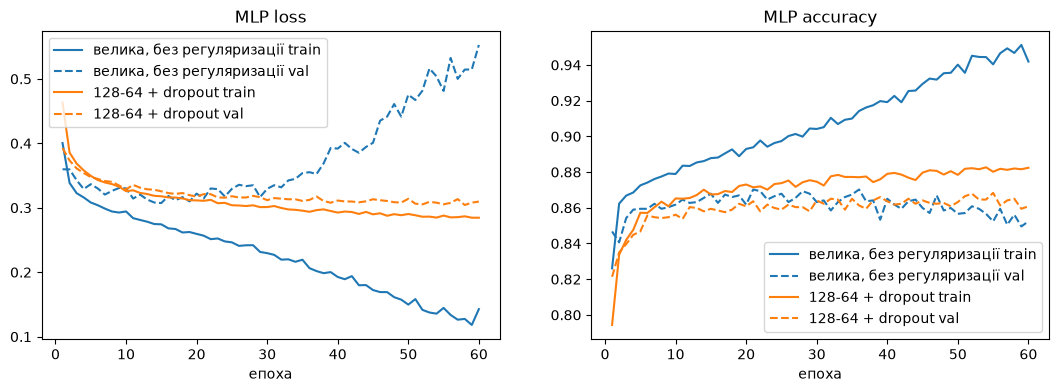

In [5]:
mlp = MLP(10, hidden=(128, 64), dropout=0.2)
h_mlp = train_model(mlp, tr_loader, val_loader, epochs=60, lr=1e-3, weight_decay=1e-4)
plot_hist({'велика, без регуляризації': h_big, '128-64 + dropout': h_mlp}, 'MLP')

**Велика мережа без регуляризації** - класичне перенавчання. Перші ~15 епох train і val loss падають разом (найменший val loss 0.307 на 15 епосі), а далі train loss продовжує падати до 0.12, train accuracy росте до 0.95, а val loss росте до 0.55 і val accuracy падає з 0.87 до 0.85. Мережа запамʼятовує тренувальні дані, а не вчиться узагальнювати. Через те, що я зберігаю ваги з найменшим val loss, в кінці беруться ваги з 15 епохи.

**Менша мережа 128-64 з Dropout(0.2) і weight decay** - перенавчання нема: train і val loss йдуть майже поруч весь час (0.285 і 0.31 на 60 епосі), val loss повільно падає до кінця. Різниця train/val accuracy невелика (0.88 / 0.86). Ця модель і йде далі на test.

In [6]:
yt, yp = predict(mlp, test_loader)
acc_mlp = accuracy_score(yt, yp)
print('MLP test accuracy:', round(acc_mlp, 4))
print(classification_report(yt, yp, target_names=['g', 'h'], digits=3))

MLP test accuracy: 0.8741
              precision    recall  f1-score   support

           g      0.871     0.947     0.908      3083
           h      0.882     0.737     0.803      1644

    accuracy                          0.874      4727
   macro avg      0.876     0.842     0.855      4727
weighted avg      0.875     0.874     0.871      4727



### Порівняння з класичними моделями з лаби 1

In [7]:
sc = StandardScaler().fit(X_train)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
svm = SVC(C=10, gamma=0.1).fit(sc.transform(X_train), y_train)
comp = pd.DataFrame({
    'модель': ['Random Forest (лаба 1)', 'SVM C=10 gamma=0.1 (лаба 1)', 'MLP 128-64 + dropout'],
    'accuracy': [accuracy_score(y_test, rf.predict(X_test)),
                 accuracy_score(y_test, svm.predict(sc.transform(X_test))), acc_mlp],
}).round(4)
comp

,модель,accuracy
0,Random Forest (лаба 1),0.8845
1,SVM C=10 gamma=0.1 (лаба 1),0.8748
2,MLP 128-64 + dropout,0.8741


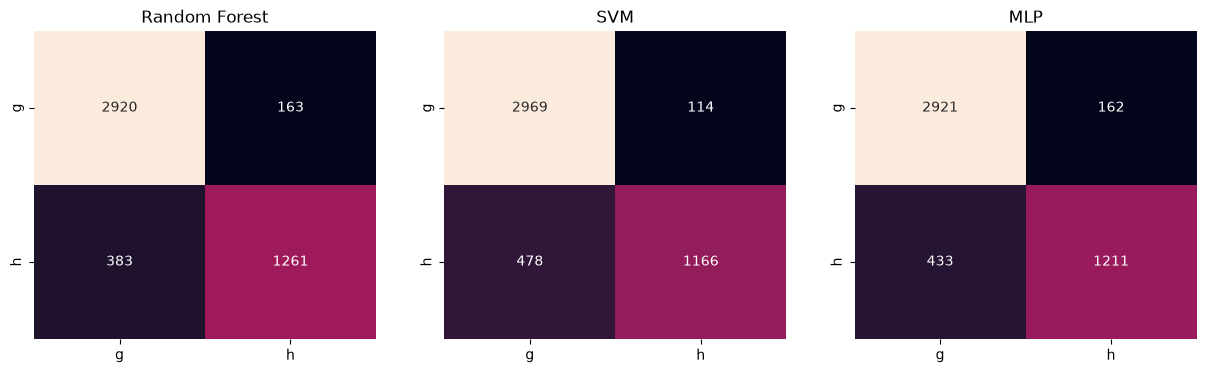

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, p) in zip(ax, [('Random Forest', rf.predict(X_test)), ('SVM', svm.predict(sc.transform(X_test))), ('MLP', yp)]):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cbar=False, ax=a,
                xticklabels=['g', 'h'], yticklabels=['g', 'h'])
    a.set_title(name)
plt.show()

MLP дав 0.874 - стільки ж, скільки SVM (0.875), і трохи менше ніж Random Forest (0.885). Помилки такі самі як в лабі 1: гамму знаходить добре (recall 0.95), а адронів пропускає (recall 0.74 проти 0.77 у RF).

Тобто для табличних даних з 10 ознаками нейромережа нічого не виграла. Дерева (RF, бустинг) на таблицях зазвичай не гірші за MLP, а налаштовувати їх простіше: не треба масштабування, підбору lr, кількості епох і регуляризації. Нейромережі сильні там, де ознаки треба знайти самим - зображення, тексти (частини 2 і 3).

## 2. Згорткові мережі (CNN) на EuroSAT

EuroSAT (https://www.kaggle.com/datasets/apollo2506/eurosat-dataset) - знімки супутника Sentinel-2, RGB 64x64. 27 000 зображень, 10 класів типів місцевості. MNIST і CIFAR брати не можна, а цей датасет теж невеликий (картинки 64x64), тому вчиться швидко, але задача складніша ніж цифри.

In [9]:
ds_raw = torchvision.datasets.EuroSAT(root='data', download=True)
classes = ds_raw.classes
targets = np.array(ds_raw.targets)
print(len(ds_raw), 'зображень,', ds_raw[0][0].size)
print(pd.Series(targets).map(dict(enumerate(classes))).value_counts())

27000 зображень, (64, 64)
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Residential             3000
SeaLake                 3000
Highway                 2500
Industrial              2500
PermanentCrop           2500
River                   2500
Pasture                 2000
Name: count, dtype: int64


27 000 RGB знімків 64x64, 10 класів: AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake. В класах від 2000 до 3000 картинок - невеликий дисбаланс, але не критичний, тому нічого з ним не роблю (зате split стратифікований).

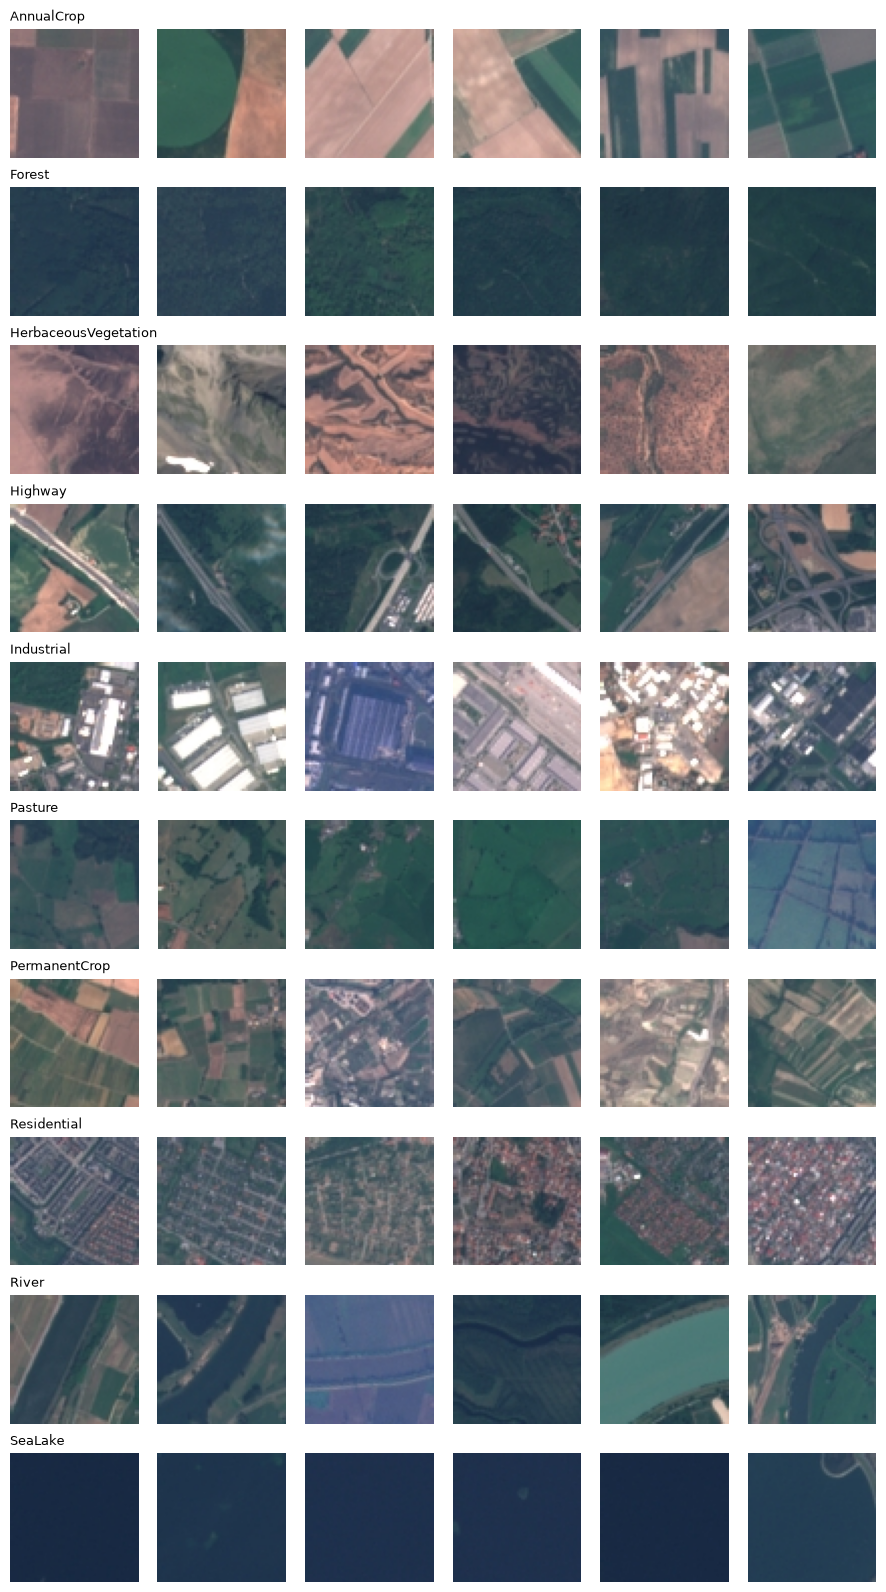

In [10]:
fig, ax = plt.subplots(len(classes), 6, figsize=(9, 16))
for i, c in enumerate(classes):
    idx = np.where(targets == i)[0][:6]
    for j, k in enumerate(idx):
        ax[i, j].imshow(ds_raw[k][0]); ax[i, j].axis('off')
    ax[i, 0].set_title(c, fontsize=9, loc='left')
plt.tight_layout()
plt.show()

Розбиття: 70% train, 15% val, 15% test (стратифіковано). Для навчання з нуля - нормалізація по середньому датасету і проста аугментація (фліпи і повороти на 90 градусів - для знімка згори напрям не важливий). Для pretrained моделі нормалізація ImageNet, бо вона так навчалась.

In [11]:
idx_all = np.arange(len(targets))
i_tr, i_tmp = train_test_split(idx_all, test_size=0.3, random_state=42, stratify=targets)
i_val, i_te = train_test_split(i_tmp, test_size=0.5, random_state=42, stratify=targets[i_tmp])
print(len(i_tr), len(i_val), len(i_te))

class Rot90:
    def __call__(self, x):
        return torch.rot90(x, int(torch.randint(0, 4, (1,))), dims=(1, 2))

def make_ds(tf):
    return torchvision.datasets.EuroSAT(root='data', transform=tf)

eur_mean, eur_std = [0.345, 0.380, 0.408], [0.203, 0.137, 0.116]
tf_train = transforms.Compose([transforms.ToTensor(), transforms.RandomHorizontalFlip(), Rot90(), transforms.Normalize(eur_mean, eur_std)])
tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(eur_mean, eur_std)])

def loaders(tf_tr, tf_ev, train_idx, bs=128):
    return (DataLoader(Subset(make_ds(tf_tr), train_idx), batch_size=bs, shuffle=True, num_workers=0),
            DataLoader(Subset(make_ds(tf_ev), i_val), batch_size=256),
            DataLoader(Subset(make_ds(tf_ev), i_te), batch_size=256))

18900 4050 4050


### а) Проста CNN з нуля

2193674 параметрів


ep  1  train loss 1.1706 acc 0.5979 | val loss 0.8644 acc 0.6857


ep  2  train loss 0.7409 acc 0.7357 | val loss 0.6147 acc 0.7756


ep  3  train loss 0.6538 acc 0.7688 | val loss 0.5748 acc 0.8037


ep  4  train loss 0.5360 acc 0.8140 | val loss 0.7723 acc 0.7523


ep  5  train loss 0.5035 acc 0.8294 | val loss 0.5207 acc 0.8185


... (11 outputs left out)

ep 17  train loss 0.2672 acc 0.9088 | val loss 0.4115 acc 0.8605


ep 18  train loss 0.2595 acc 0.9124 | val loss 0.3996 acc 0.8612


ep 19  train loss 0.2564 acc 0.9138 | val loss 0.2260 acc 0.9217


ep 20  train loss 0.2438 acc 0.9165 | val loss 0.3154 acc 0.8891


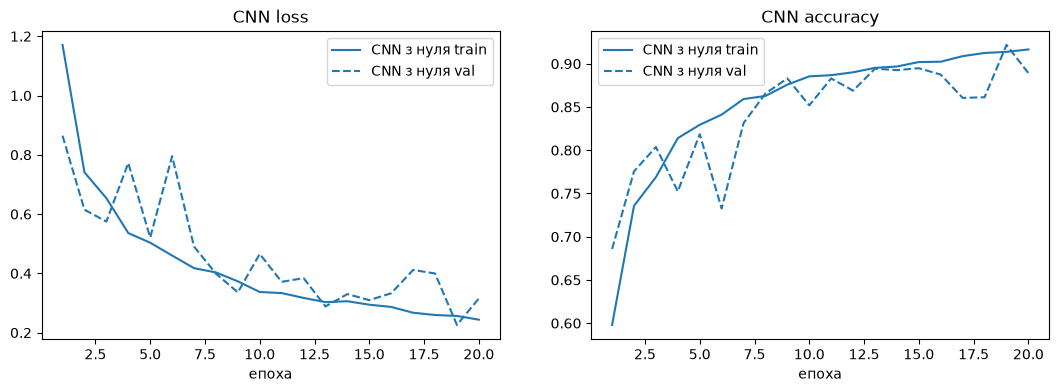

In [12]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))   # 64 -> 32 -> 16 -> 8
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 8 * 8, 256),
                                        nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SimpleCNN()
print(sum(p.numel() for p in cnn.parameters()), 'параметрів')
tr_l, val_l, te_l = loaders(tf_train, tf_eval, i_tr)
h_cnn = train_model(cnn, tr_l, val_l, epochs=20, lr=1e-3)
plot_hist({'CNN з нуля': h_cnn}, 'CNN')

3 згорткових блоки (conv 3x3 -> BatchNorm -> ReLU -> MaxPool), кожен зменшує картинку вдвічі і збільшує кількість каналів. Потім один прихований fully connected шар і вихід на 10 класів.

В мережі 2.19 млн параметрів, з них 2.1 млн - перший fully connected шар (128 * 8 * 8 -> 256), згорткові шари маленькі.

Train loss плавно падає від 1.17 до 0.24, val accuracy виросла з 0.69 до ~0.9. Val loss дуже скаче (наприклад 0.77 на 4 епосі і 0.80 на 6), хоча загальний тренд вниз. Це через BatchNorm (на валідації використовуються накопичені середні, які ще "плавають" на початку) і постійний lr 1e-3. Перенавчання нема: train і val loss в кінці близькі (0.24 і 0.23-0.31), train accuracy 0.92 - аугментація (фліпи/повороти) і dropout не дають мережі запамʼятати картинки. Мережа ще не дійшла до межі: якби вчити більше епох або зменшувати lr, результат був би трохи кращим.

### б) Pretrained ResNet18

ResNet18, навчений на ImageNet. Замінюю останній шар `fc` (1000 класів) на новий на 10 класів. Картинки збільшую до 128x128 - ResNet розрахований на більші зображення, на 64x64 після всіх зменшень лишається карта 2x2.
Донавчаю всю мережу, але з маленьким learning rate (1e-4), щоб не зіпсувати те, що вона вже вміє.

ep  1  train loss 0.2698 acc 0.9162 | val loss 0.0882 acc 0.9699


ep  2  train loss 0.0817 acc 0.9741 | val loss 0.0852 acc 0.9723


ep  3  train loss 0.0647 acc 0.9788 | val loss 0.0708 acc 0.9763


ep  4  train loss 0.0487 acc 0.9824 | val loss 0.0742 acc 0.9760


ep  5  train loss 0.0449 acc 0.9852 | val loss 0.0753 acc 0.9783


ep  6  train loss 0.0381 acc 0.9875 | val loss 0.0954 acc 0.9689


ep  7  train loss 0.0320 acc 0.9892 | val loss 0.0737 acc 0.9768


ep  8  train loss 0.0313 acc 0.9895 | val loss 0.0630 acc 0.9785


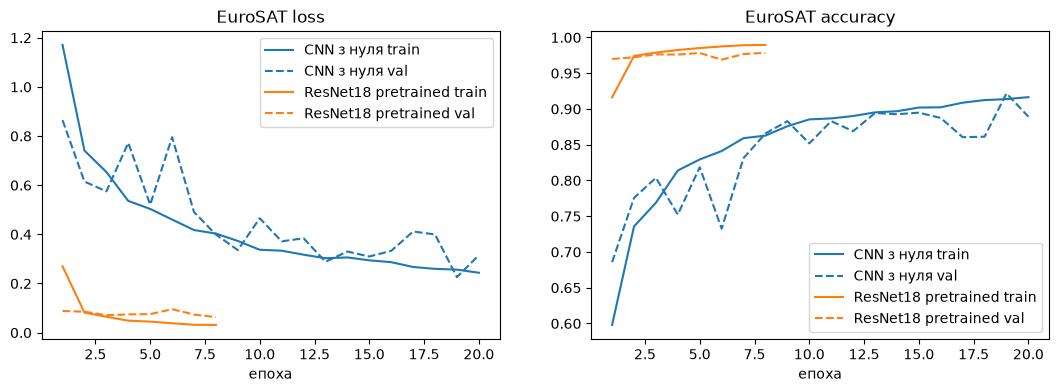

In [13]:
im_mean, im_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train_r = transforms.Compose([transforms.Resize(128), transforms.ToTensor(), transforms.RandomHorizontalFlip(), Rot90(), transforms.Normalize(im_mean, im_std)])
tf_eval_r = transforms.Compose([transforms.Resize(128), transforms.ToTensor(), transforms.Normalize(im_mean, im_std)])

def make_resnet():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m

resnet = make_resnet()
tr_r, val_r, te_r = loaders(tf_train_r, tf_eval_r, i_tr)
h_res = train_model(resnet, tr_r, val_r, epochs=8, lr=1e-4)
plot_hist({'CNN з нуля': h_cnn, 'ResNet18 pretrained': h_res}, 'EuroSAT')

ResNet вже після першої епохи має val accuracy 0.97 - вище, ніж CNN з нуля після всіх 20 епох. Далі val loss тримається на рівні 0.06-0.09, найменший 0.063 на 8 епосі. Train accuracy 0.99, val 0.98 - невеликий розрив, сильного перенавчання нема (маленький lr не дає швидко "перебудувати" мережу).

### Порівняння на test

In [14]:
res_tab = []
preds_img = {}
for name, m, tl, h in [('CNN з нуля', cnn, te_l, h_cnn), ('ResNet18 pretrained', resnet, te_r, h_res)]:
    yt_i, yp_i = predict(m, tl)
    preds_img[name] = (yt_i, yp_i)
    first = h['val_acc'][0]
    ep90 = next((i + 1 for i, a in enumerate(h['val_acc']) if a >= 0.9), None)
    res_tab.append({'модель': name, 'test accuracy': round(accuracy_score(yt_i, yp_i), 4),
                    'val acc після 1 епохи': round(first, 3), 'епох до val acc 0.9': ep90,
                    'епох': len(h['val_acc']), 'час, с': round(h['time']), 'с/епоху': round(h['time'] / len(h['val_acc']), 1)})
pd.DataFrame(res_tab)

,модель,test accuracy,val acc після 1 епохи,епох до val acc 0.9,епох,"час, с",с/епоху
0,CNN з нуля,0.9326,0.686,19,20,208,10.4
1,ResNet18 pretrained,0.9795,0.970,1,8,221,27.6


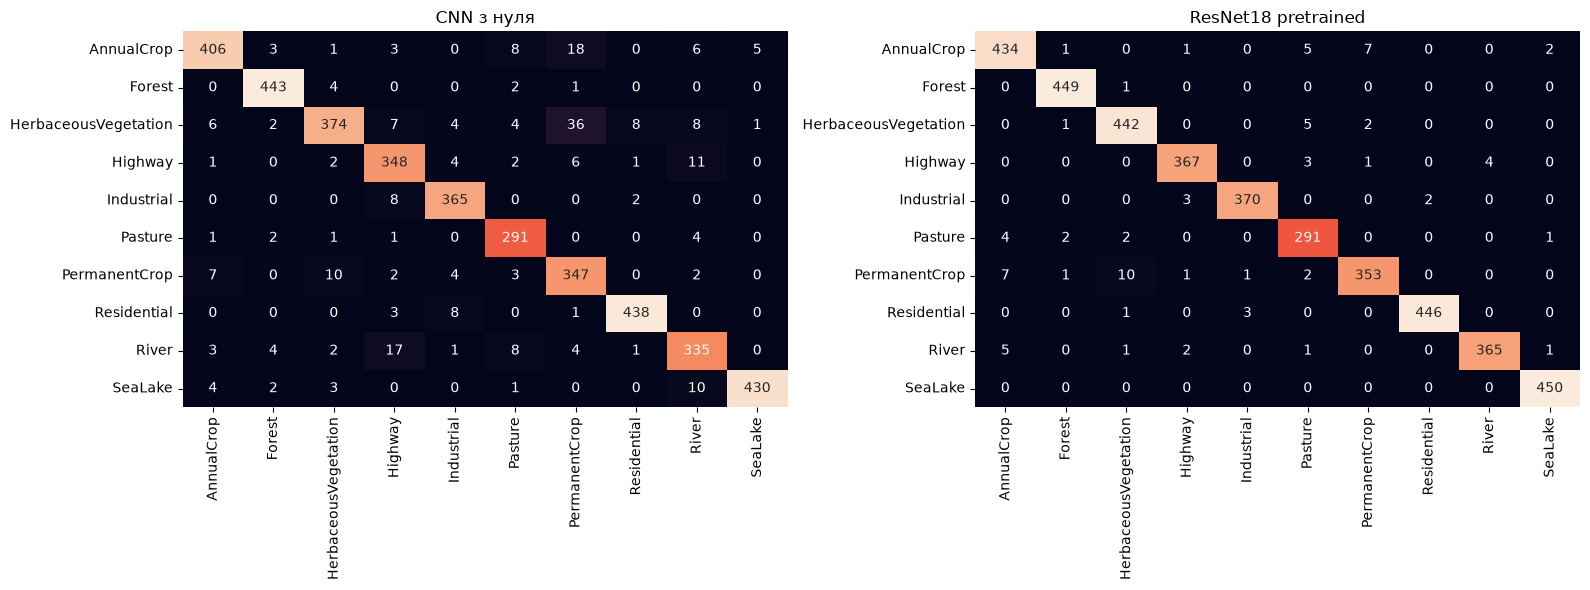

                      precision    recall  f1-score   support

          AnnualCrop      0.949     0.902     0.925       450
              Forest      0.971     0.984     0.978       450
HerbaceousVegetation      0.942     0.831     0.883       450
             Highway      0.895     0.928     0.911       375
          Industrial      0.946     0.973     0.959       375
             Pasture      0.912     0.970     0.940       300
       PermanentCrop      0.840     0.925     0.881       375
         Residential      0.973     0.973     0.973       450
               River      0.891     0.893     0.892       375
             SeaLake      0.986     0.956     0.971       450

            accuracy                          0.933      4050
           macro avg      0.931     0.934     0.931      4050
        weighted avg      0.934     0.933     0.933      4050



In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, (name, (yt_i, yp_i)) in zip(ax, preds_img.items()):
    sns.heatmap(confusion_matrix(yt_i, yp_i), annot=True, fmt='d', cbar=False, ax=a,
                xticklabels=classes, yticklabels=classes)
    a.set_title(name)
plt.tight_layout()
plt.show()
print(classification_report(*preds_img['CNN з нуля'], target_names=classes, digits=3))

| | CNN з нуля | ResNet18 pretrained |
|---|---|---|
| test accuracy | 0.933 | **0.980** |
| val acc після 1 епохи | 0.69 | 0.97 |
| епох до val acc 0.9 | 19 | 1 |
| час (всього / на епоху) | ~3.5 хв / 10 с | ~3.7 хв / 28 с |

- **Якість:** pretrained модель краща на 4.7 п.п. і помиляється в 3 рази рідше (83 помилки проти 273 на 4050 картинках).
- **Збіжність:** ResNet майже готовий після 1 епохи, бо вже вміє виділяти краї, текстури, форми з ImageNet - треба тільки навчити новий останній шар і трохи підлаштувати решту. CNN з нуля вчиться всьому сама, і її val loss нестабільний.
- **Швидкість:** одна епоха ResNet в ~2.7 рази довша (11 млн параметрів і картинки 128x128), але епох треба в рази менше, тому загальний час приблизно однаковий.
- **Помилки** у обох моделей між схожими класами: різні типи полів (HerbaceousVegetation / PermanentCrop / AnnualCrop - у CNN 36 HerbaceousVegetation прийнято за PermanentCrop) і лінійні обʼєкти River / Highway. ResNet майже прибрав плутанину River-Highway і SeaLake-River.

### Вплив обсягу тренувальних даних

Вчу обидві моделі на 2%, 10% і 30% від train (val і test ті самі) і дивлюсь як падає якість.

In [16]:
size_rows = []
for frac in [0.02, 0.1, 0.3]:
    sub, _ = train_test_split(i_tr, train_size=frac, random_state=42, stratify=targets[i_tr])
    for name in ['CNN з нуля', 'ResNet18 pretrained']:
        torch.manual_seed(42)
        if name == 'CNN з нуля':
            m = SimpleCNN(); tl, vl, tel = loaders(tf_train, tf_eval, sub, bs=64); ep, lr = 20, 1e-3
        else:
            m = make_resnet(); tl, vl, tel = loaders(tf_train_r, tf_eval_r, sub, bs=64); ep, lr = 8, 1e-4
        print(f'--- {name}, {frac:.0%} train ({len(sub)} картинок)')
        train_model(m, tl, vl, epochs=ep, lr=lr)
        yt_i, yp_i = predict(m, tel)
        size_rows.append({'частка train': frac, 'картинок': len(sub), 'модель': name, 'test accuracy': accuracy_score(yt_i, yp_i)})

for name, (yt_i, yp_i) in preds_img.items():
    size_rows.append({'частка train': 1.0, 'картинок': len(i_tr), 'модель': name, 'test accuracy': accuracy_score(yt_i, yp_i)})
size_df = pd.DataFrame(size_rows)
print(size_df.pivot(index='картинок', columns='модель', values='test accuracy').round(4))

--- CNN з нуля, 2% train (378 картинок)


ep  1  train loss 3.3820 acc 0.2116 | val loss 2.0062 acc 0.2877


ep  2  train loss 2.1158 acc 0.3254 | val loss 1.9332 acc 0.2835


ep  3  train loss 1.6111 acc 0.4418 | val loss 1.8221 acc 0.3328


ep  4  train loss 1.4219 acc 0.4974 | val loss 1.6460 acc 0.3773


ep  5  train loss 1.2856 acc 0.5344 | val loss 1.3335 acc 0.5183


... (81 outputs left out)

ep  6  train loss 0.0540 acc 0.9831 | val loss 0.0892 acc 0.9701


ep  7  train loss 0.0461 acc 0.9850 | val loss 0.0951 acc 0.9701


ep  8  train loss 0.0434 acc 0.9854 | val loss 0.0928 acc 0.9686


модель    CNN з нуля  ResNet18 pretrained
картинок                                 
378           0.6995               0.9235
1890          0.8030               0.9610
5670          0.8798               0.9736
18900         0.9326               0.9795


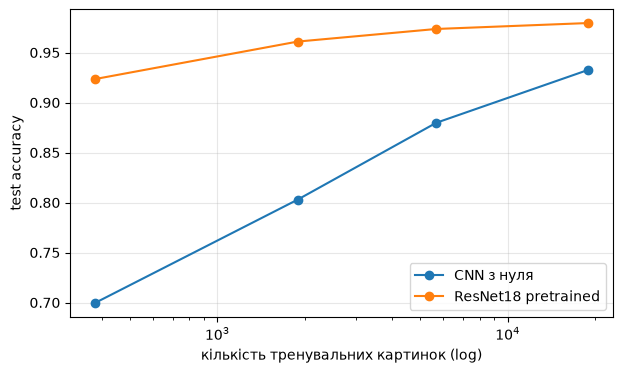

In [17]:
plt.figure(figsize=(7, 4))
for name, g in size_df.groupby('модель'):
    g = g.sort_values('картинок')
    plt.plot(g['картинок'], g['test accuracy'], 'o-', label=name)
plt.xscale('log'); plt.xlabel('кількість тренувальних картинок (log)'); plt.ylabel('test accuracy')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

| картинок в train | CNN з нуля | ResNet18 | різниця |
|---|---|---|---|
| 378 (2%) | 0.700 | 0.924 | 22 п.п. |
| 1 890 (10%) | 0.803 | 0.961 | 16 п.п. |
| 5 670 (30%) | 0.880 | 0.974 | 9 п.п. |
| 18 900 (100%) | 0.933 | 0.980 | 5 п.п. |

Чим менше даних, тим більша перевага pretrained моделі. ResNet, навчений на 378 картинках (38 на клас), дає 0.92 - краще, ніж CNN з нуля на 5670 картинках. CNN з нуля дуже залежить від обсягу даних, а pretrained модель вже має знання про зображення і їй достатньо кількох прикладів на клас. З ростом даних різниця зменшується, бо CNN з нуля теж встигає вивчити потрібні ознаки.

## 3. Класифікація текстів (RNN)

Той самий датасет що в лабі 2 - AG News, 3 класи (World, Sports, Sci/Tech), 30 тис. train і 5700 test.

In [18]:
train = pd.read_csv('../lab2/ag_news_3cls_train.csv')
test = pd.read_csv('../lab2/ag_news_3cls_test.csv')
for d in (train, test):
    d['text'] = d['title'] + '. ' + d['description']
lab2id = {'World': 0, 'Sports': 1, 'Sci/Tech': 2}

def tokenize(s):
    s = s.lower()
    s = re.sub(r'&[a-z]+;|#\d+;|<[^>]+>', ' ', s)
    return re.findall(r"[a-z]+(?:'[a-z]+)?", s)

train['tok'] = train['text'].apply(tokenize)
test['tok'] = test['text'].apply(tokenize)
print(train['tok'][0])
lens = train['tok'].str.len()
print(lens.describe())

["ching's", 'late', 'goal', 'rescues', 'u', 's', 'in', 'soccer', 'world', 'cup', 'qualifier', 'although', 'the', 'visitors', 'did', 'not', 'get', 'a', 'victory', 'the', 'united', 'states', 'is', 'still', 'in', 'a', 'good', 'position', 'after', 'what', 'figured', 'to', 'be', 'the', 'most', 'threatening', 'game', 'of', 'the', 'regional', 'semifinal', 'round']
count    30000.000000
mean        37.926600
std         11.112578
min         12.000000
25%         31.000000
50%         37.000000
75%         43.000000
max        176.000000
Name: tok, dtype: float64


Передобробка для нейромережі інша ніж в лабі 2: стоп-слова не видаляю, бо LSTM читає послідовність і службові слова теж дають контекст. Тільки нижній регістр, прибрав html-залишки, токенізація регулярним виразом по словах.

In [19]:
cnt = Counter(w for t in train['tok'] for w in t)
vocab = ['<pad>', '<unk>'] + [w for w, c in cnt.most_common() if c >= 2]
w2i = {w: i for i, w in enumerate(vocab)}
print('слів всього:', len(cnt), ' у словнику (зустрічається >= 2 рази):', len(vocab))

MAX_LEN = 60
def encode(tokens):
    ids = [w2i.get(w, 1) for w in tokens][:MAX_LEN]          # truncation
    return ids + [0] * (MAX_LEN - len(ids))                  # padding

def to_tensor(d):
    return torch.tensor(np.stack(d['tok'].apply(encode))), torch.tensor(d['label'].map(lab2id).values)

X_all, y_all = to_tensor(train)
X_te_t, y_te_t = to_tensor(test)
idx_tr, idx_val = train_test_split(np.arange(len(y_all)), test_size=0.15, random_state=42, stratify=y_all)
txt_tr = DataLoader(TensorDataset(X_all[idx_tr], y_all[idx_tr]), batch_size=128, shuffle=True)
txt_val = DataLoader(TensorDataset(X_all[idx_val], y_all[idx_val]), batch_size=512)
txt_te = DataLoader(TensorDataset(X_te_t, y_te_t), batch_size=512)
print(train['tok'][0][:12]); print(X_all[0][:12])
print('частка текстів довших за', MAX_LEN, ':', round((lens > MAX_LEN).mean(), 3))

слів всього: 38786  у словнику (зустрічається >= 2 рази): 25203


["ching's", 'late', 'goal', 'rescues', 'u', 's', 'in', 'soccer', 'world', 'cup', 'qualifier', 'although']
tensor([    1,   384,   649, 19623,    53,    10,     6,   651,    47,   115,
         1989,  1662])
частка текстів довших за 60 : 0.032


Словник будую тільки по train, рідкісні слова (1 раз) і невідомі -> `<unk>` (індекс 1). Довжину вирівнюю до 60 токенів: коротші доповнюю `<pad>` (0), довші обрізаю - таких лише кілька відсотків.

In [20]:
class TextRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden=128, n_classes=3, emb_weights=None, freeze=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if emb_weights is not None:
            self.emb.weight.data.copy_(emb_weights)
            self.emb.weight.requires_grad = not freeze
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(2 * hidden, n_classes)

    def forward(self, x):
        mask = (x != 0).unsqueeze(-1).float()
        out, _ = self.lstm(self.emb(x))
        # усереднення виходів LSTM тільки по справжніх токенах (без паддінгу)
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(self.drop(pooled))

Embedding -> двонаправлений LSTM (128 в кожну сторону) -> усереднення по токенах -> Dropout -> Linear на 3 класи. Паддінг маскую, щоб нулі в кінці не розмивали середнє.

### а) Embedding з випадковими вагами

In [21]:
torch.manual_seed(42)
rnn_rand = TextRNN(len(vocab))
h_rand = train_model(rnn_rand, txt_tr, txt_val, epochs=8, lr=1e-3)

ep  1  train loss 0.5703 acc 0.7612 | val loss 0.3220 acc 0.8882


ep  2  train loss 0.2325 acc 0.9218 | val loss 0.2435 acc 0.9187


ep  3  train loss 0.1514 acc 0.9510 | val loss 0.2336 acc 0.9240


ep  4  train loss 0.1055 acc 0.9691 | val loss 0.2537 acc 0.9276


ep  5  train loss 0.0773 acc 0.9775 | val loss 0.2236 acc 0.9307


ep  6  train loss 0.0506 acc 0.9861 | val loss 0.2458 acc 0.9300


ep  7  train loss 0.0410 acc 0.9885 | val loss 0.3280 acc 0.9211


ep  8  train loss 0.0246 acc 0.9936 | val loss 0.3189 acc 0.9260


### б) Pretrained GloVe

In [22]:
import gensim.downloader as api
glove = api.load('glove-wiki-gigaword-100')     # GloVe 6B, 100-вимірні вектори, 400 тис. слів

emb_w = torch.randn(len(vocab), 100) * 0.1
emb_w[0] = 0
found = 0
for w, i in w2i.items():
    if w in glove:
        emb_w[i] = torch.tensor(glove[w]); found += 1
print(f'знайдено в GloVe: {found} з {len(vocab)} ({found/len(vocab):.1%})')

знайдено в GloVe: 24130 з 25203 (95.7%)


Слова, яких немає в GloVe, ініціалізую випадково (малими числами), `<pad>` - нулі.

ep  1  train loss 0.2688 acc 0.9152 | val loss 0.1586 acc 0.9478


ep  2  train loss 0.1414 acc 0.9570 | val loss 0.1401 acc 0.9567


ep  3  train loss 0.1094 acc 0.9685 | val loss 0.1444 acc 0.9580


ep  4  train loss 0.0848 acc 0.9766 | val loss 0.1536 acc 0.9544


ep  5  train loss 0.0661 acc 0.9827 | val loss 0.1537 acc 0.9584


ep  6  train loss 0.0510 acc 0.9869 | val loss 0.1592 acc 0.9540


... (6 outputs left out)

ep  5  train loss 0.1352 acc 0.9577 | val loss 0.1402 acc 0.9536


ep  6  train loss 0.1293 acc 0.9611 | val loss 0.1342 acc 0.9533


ep  7  train loss 0.1209 acc 0.9625 | val loss 0.1362 acc 0.9544


ep  8  train loss 0.1143 acc 0.9649 | val loss 0.1372 acc 0.9542


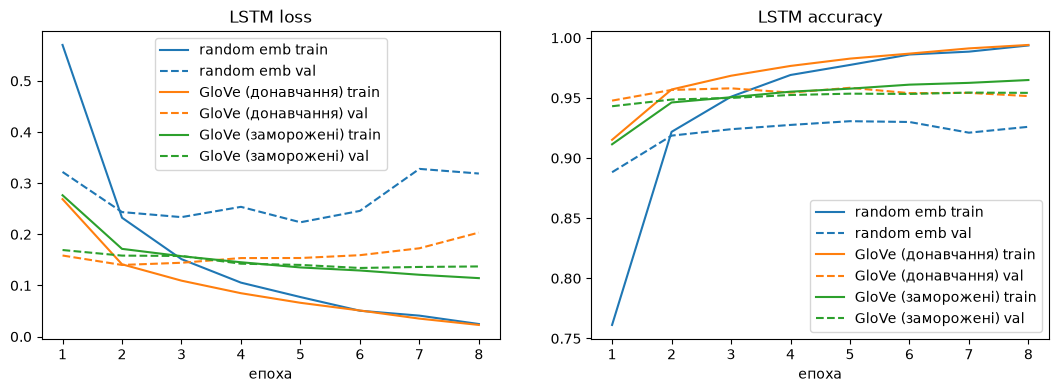

In [23]:
torch.manual_seed(42)
rnn_glove = TextRNN(len(vocab), emb_weights=emb_w, freeze=False)
h_glove = train_model(rnn_glove, txt_tr, txt_val, epochs=8, lr=1e-3)

torch.manual_seed(42)
rnn_glove_fr = TextRNN(len(vocab), emb_weights=emb_w, freeze=True)
h_glove_fr = train_model(rnn_glove_fr, txt_tr, txt_val, epochs=8, lr=1e-3)

plot_hist({'random emb': h_rand, 'GloVe (донавчання)': h_glove, 'GloVe (заморожені)': h_glove_fr}, 'LSTM')

Додатково спробував варіант, де GloVe ваги заморожені (не оновлюються) - щоб побачити, що дає саме знання з GloVe, без підлаштування під датасет.

Словник 25 203 слова, в GloVe знайшлось 95.7% з них.

- **Random embedding:** найкращий val loss 0.224 на 5 епосі, далі val loss росте (0.32 на 8), а train accuracy доходить до 0.994 - перенавчання. Ембедінги (25 тис. слів * 100 = 2.5 млн параметрів) вчаться тільки на 25 тис. текстів, і мережа починає запамʼятовувати конкретні слова з train.
- **GloVe з донавчанням:** вже після першої епохи val accuracy 0.948 (у random 0.888). Найкращий val loss 0.140 на 2 епосі, але потім він теж росте - донавчання ембедінгів так само призводить до перенавчання, просто з кращої стартової точки.
- **GloVe заморожені:** val loss падає майже до кінця (найменший 0.134 на 6 епосі), train і val криві поруч - перенавчання нема, бо ембедінги не змінюються і параметрів, які вчаться, набагато менше.

In [24]:
txt_rows = []
for name, m, h in [('LSTM + random embedding', rnn_rand, h_rand), ('LSTM + GloVe (донавчання)', rnn_glove, h_glove),
                   ('LSTM + GloVe (заморожені)', rnn_glove_fr, h_glove_fr)]:
    yt_t, yp_t = predict(m, txt_te)
    txt_rows.append({'модель': name, 'test accuracy': round(accuracy_score(yt_t, yp_t), 4),
                     'val acc після 1 епохи': round(h['val_acc'][0], 4), 'найкращий val loss': round(min(h['val_loss']), 4),
                     'епоха з найкращим val loss': int(np.argmin(h['val_loss'])) + 1, 'час, с': round(h['time'])})
txt_rows.append({'модель': 'TF-IDF + Naive Bayes (лаба 2)', 'test accuracy': 0.9554})
txt_rows.append({'модель': 'TF-IDF + Logistic Regression (лаба 2)', 'test accuracy': 0.9504})
pd.DataFrame(txt_rows)

,модель,test accuracy,val acc після 1 епохи,найкращий val loss,епоха з найкращим val loss,"час, с"
0,LSTM + random embedding,0.9212,0.8882,0.2236,5.0,8.0
1,LSTM + GloVe (донавчання),0.9551,0.9478,0.1401,2.0,8.0
2,LSTM + GloVe (заморожені),0.9560,0.9431,0.1342,6.0,7.0
3,TF-IDF + Naive Bayes (лаба 2),0.9554,NaN,NaN,NaN,NaN
4,TF-IDF + Logistic Regression (лаба 2),0.9504,NaN,NaN,NaN,NaN


              precision    recall  f1-score   support

       World      0.960     0.920     0.940      1900
      Sports      0.950     0.988     0.969      1900
    Sci/Tech      0.955     0.957     0.956      1900

    accuracy                          0.955      5700
   macro avg      0.955     0.955     0.955      5700
weighted avg      0.955     0.955     0.955      5700



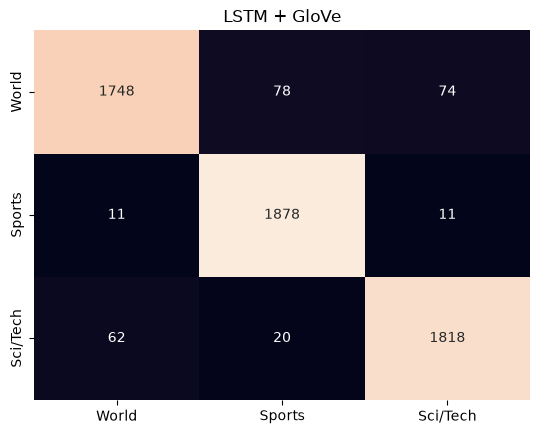

In [25]:
yt_t, yp_t = predict(rnn_glove, txt_te)
print(classification_report(yt_t, yp_t, target_names=list(lab2id), digits=3))
sns.heatmap(confusion_matrix(yt_t, yp_t), annot=True, fmt='d', cbar=False, xticklabels=list(lab2id), yticklabels=list(lab2id))
plt.title('LSTM + GloVe'); plt.show()

- **Якість:** GloVe дав +3.4 п.п. (0.955-0.956 проти 0.921 з random ембедінгами). GloVe навчений на 6 млрд слів і вже "знає", що схожі слова (football / soccer, microsoft / ibm) мають близькі вектори, тому модель краще узагальнює і на словах, які в train зустрічались рідко. Random ембедінгам на 25 тис. текстах вивчити таке неможливо.
- **Швидкість і стабільність:** з GloVe модель вже після 1 епохи (val acc 0.948) краща, ніж random за весь час навчання (максимум 0.931). Найстабільніший варіант - заморожені GloVe: val loss не росте, нема перенавчання. Час навчання однаковий (~8 с на 8 епох на GPU).
- **Порівняння з лабою 2:** LSTM + GloVe (0.956) = TF-IDF + Naive Bayes (0.955). Для класифікації новин за темою вистачає ключових слів, а порядок слів, який враховує LSTM, майже нічого не додає. Тому тут простий TF-IDF не гірший і вчиться миттєво.

## Висновок

1. **MLP на табличних даних (MAGIC):** 0.874 - на рівні SVM (0.875), трохи гірше Random Forest (0.885). Велика мережа без регуляризації явно перенавчається (val loss росте з 15 епохи), Dropout і weight decay це виправляють. Для таблиць нейромережа не дала переваги над класичними методами.
2. **CNN на EuroSAT:** проста CNN з нуля - 0.933, pretrained ResNet18 - 0.980. Pretrained модель збігається за 1 епоху, а не за ~20, і особливо виграє на малих даних: на 378 картинках 0.92 проти 0.70. Transfer learning - найкращий вибір, коли даних мало.
3. **LSTM на AG News:** random ембедінги - 0.921 з перенавчанням, GloVe - 0.956 і стабільне навчання. Pretrained ембедінги дають і кращу якість, і швидшу збіжність. Але для цієї задачі LSTM з GloVe лише зрівнявся з TF-IDF з лаби 2 - для класифікації за темою достатньо ключових слів.

Загальне: нейромережі виграють там, де ознаки треба знайти з сирих даних (зображення), а pretrained моделі (ResNet, GloVe) дають великий приріст, коли власних даних небагато.